
# BHA Dental Clinic Analytics — Python Analysis

## 1. Project Overview

This project analyzes fictional dental clinic transaction data for January–March 2026. It demonstrates how Python can be used to validate healthcare financial data, calculate key performance indicators (KPIs), and generate treatment-level and monthly summaries.

The analysis supports the financial performance dashboard developed in Microsoft Power BI as part of the Bhardwaj Healthcare Analytics (BHA) portfolio.

> **Data disclaimer:** The dataset contains 35 fictional demonstration transactions. It does not represent actual clinic performance or real patient transactions.

## 2. Business Objectives

- Validate transaction records and financial calculations.
- Calculate total charges, collections, and outstanding balances.
- Measure the overall collection rate.
- Compare financial performance across treatment categories.
- Analyze monthly collection trends.
- Reconcile Python results with the Power BI dashboard.

## 3. Dataset

**Source file:** `BHA_Dental_Clinic_Cleaned.xlsx`  
**Worksheet:** `Cleaned_Transactions`  
**Reporting period:** January–March 2026  
**Expected records:** 35  
**Currency:** Indian Rupees (INR)

### Key Fields

| Column | Description |
|---|---|
| `Transaction_ID` | Unique transaction identifier |
| `Visit_ID` | Visit identifier |
| `Visit_Date` | Date of the dental visit |
| `Patient_ID` | Fictional patient identifier |
| `Treatment_Category` | Type of dental treatment |
| `Amount_Charged` | Amount charged for the transaction |
| `Amount_Collected` | Amount collected for the transaction |
| `Outstanding_Amount` | Outstanding amount recorded for the transaction |

## 4. Tools and Libraries

- Python
- pandas — data loading, validation, and analysis
- pathlib — file path management
- Jupyter Notebook — reproducible analysis

## 5. Analysis Workflow

1. Import libraries and locate the cleaned workbook.
2. Load the transaction data.
3. Inspect the dataset structure and data types.
4. Check missing values, duplicate records, and financial consistency.
5. Calculate overall financial KPIs.
6. Summarize charges, collections, and outstanding balances by treatment.
7. Analyze monthly collections.
8. Reconcile the results with the Power BI dashboard.

## 6. Expected Financial Reconciliation

The Power BI dashboard currently reports the following values, which will be independently recalculated in Python.

| Metric | Expected Value |
|---|---:|
| Total Charges | ₹80,300 |
| Total Collections | ₹61,100 |
| Outstanding Balance | ₹19,200 |
| Collection Rate | 76.1% |

These are validation targets, not hard-coded analytical results. The notebook will calculate the values directly from the cleaned dataset.

## 7. Business Questions

- How much was charged and collected during the reporting period?
- What proportion of charges was collected?
- Which treatment categories have the highest outstanding balances?
- How did collections change from January to March 2026?
- Do the calculated results reconcile with the Power BI dashboard?

## 8. Limitations

The analysis uses a small fictional dataset covering three months. Findings are intended to demonstrate analytical methods and should not be interpreted as evidence of actual clinic performance or long-term trends.

## 9. Results

The results, validation findings, and business insights will be documented here after the analysis is completed.


In [1]:
import pandas as pd
from pathlib import Path
print("pandas version:", pd.__version__)
print("Python analysis environment is ready.")

pandas version: 3.0.5
Python analysis environment is ready.


In [2]:
# Define the project directory
project_dir = Path.home() / "Desktop" / "BHA_Dental_Clinic_Analytics"

# Define the cleaned Excel workbook path
cleaned_file = (
    project_dir
    / "02_Cleaned_Data"
    / "BHA_Dental_Clinic_Cleaned.xlsx"
)

# Verify that the workbook exists
print("Project directory:", project_dir)
print("Cleaned workbook:", cleaned_file)
print("Workbook exists:", cleaned_file.exists())


Project directory: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics
Cleaned workbook: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\02_Cleaned_Data\BHA_Dental_Clinic_Cleaned.xlsx
Workbook exists: True


In [5]:

# Load the cleaned transaction worksheet
df = pd.read_excel(
    cleaned_file,
    sheet_name="Cleaned_Transactions"
)

# Display the dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Preview the first five records
df.head()

Number of rows: 35
Number of columns: 13


,Transaction_ID,Visit_ID,Visit_Date,Patient_ID,Treatment_Category,Amount_Charged,Amount_Collected,Outstanding_Amount,Unnamed: 8,Unnamed: 9,Unnamed: 10,Data Validation Results,Unnamed: 12
0,T001,V001,2026-01-05,P001,Consultation,500,500,0,NaN,NaN,NaN,Total transaction records,35
1,T002,V002,2026-01-06,P002,Scaling,1500,1500,0,NaN,NaN,NaN,Unique transaction IDs,35
2,T003,V003,2026-01-07,P003,RCT,4000,2500,1500,NaN,NaN,NaN,Missing required values,0
3,T004,V004,2026-01-08,P004,Extraction,1200,1200,0,NaN,NaN,NaN,Incorrect outstanding calculations,0
4,T005,V005,2026-01-09,P005,Consultation,500,0,500,NaN,NaN,NaN,Financial reconciliation checks passed,3 of 3


In [6]:
# Inspect all column names loaded from the worksheet
for column_number, column_name in enumerate(df.columns, start=1):
    print(f"{column_number}. {column_name!r}")

1. 'Transaction_ID     '
2. ' Visit_ID'
3. ' Visit_Date'
4. 'Patient_ID'
5. 'Treatment_Category'
6. 'Amount_Charged'
7. 'Amount_Collected'
8. 'Outstanding_Amount'
9. 'Unnamed: 8'
10. 'Unnamed: 9'
11. 'Unnamed: 10'
12. 'Data Validation Results'
13. 'Unnamed: 12'


In [7]:
# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

# Define the eight required transaction columns
transaction_columns = [
    "Transaction_ID",
    "Visit_ID",
    "Visit_Date",
    "Patient_ID",
    "Treatment_Category",
    "Amount_Charged",
    "Amount_Collected",
    "Outstanding_Amount"
]

# Create a separate DataFrame containing transaction data only
transactions = df[transaction_columns].copy()

# Display the cleaned structure
print("Transaction rows:", transactions.shape[0])
print("Transaction columns:", transactions.shape[1])
print("\nColumn names:")
print(transactions.columns.tolist())

# Preview the first five transaction records
transactions.head()

Transaction rows: 35
Transaction columns: 8

Column names:
['Transaction_ID', 'Visit_ID', 'Visit_Date', 'Patient_ID', 'Treatment_Category', 'Amount_Charged', 'Amount_Collected', 'Outstanding_Amount']


,Transaction_ID,Visit_ID,Visit_Date,Patient_ID,Treatment_Category,Amount_Charged,Amount_Collected,Outstanding_Amount
0,T001,V001,2026-01-05,P001,Consultation,500,500,0
1,T002,V002,2026-01-06,P002,Scaling,1500,1500,0
2,T003,V003,2026-01-07,P003,RCT,4000,2500,1500
3,T004,V004,2026-01-08,P004,Extraction,1200,1200,0
4,T005,V005,2026-01-09,P005,Consultation,500,0,500


In [8]:
# Display column data types and non-null counts
print("DATASET INFORMATION")
transactions.info()

# Count missing values in each column
print("\nMISSING VALUES BY COLUMN")
print(transactions.isnull().sum())

# Check the overall number of missing cells
print("\nTotal missing cells:", transactions.isnull().sum().sum())

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Transaction_ID      35 non-null     str           
 1   Visit_ID            35 non-null     str           
 2   Visit_Date          35 non-null     datetime64[us]
 3   Patient_ID          35 non-null     str           
 4   Treatment_Category  35 non-null     str           
 5   Amount_Charged      35 non-null     int64         
 6   Amount_Collected    35 non-null     int64         
 7   Outstanding_Amount  35 non-null     int64         
dtypes: datetime64[us](1), int64(3), str(4)
memory usage: 2.3 KB

MISSING VALUES BY COLUMN
Transaction_ID        0
Visit_ID              0
Visit_Date            0
Patient_ID            0
Treatment_Category    0
Amount_Charged        0
Amount_Collected      0
Outstanding_Amount    0
dtype: int64

Total missing cells: 0


In [9]:
# Check for duplicate transaction IDs
duplicate_transaction_ids = transactions[
    transactions["Transaction_ID"].duplicated(keep=False)
]

print(
    "Duplicate transaction IDs:",
    transactions["Transaction_ID"].duplicated().sum()
)

# Check for fully duplicated rows
print(
    "Fully duplicated rows:",
    transactions.duplicated().sum()
)

# Display any duplicate transaction IDs, if found
if not duplicate_transaction_ids.empty:
    print("\nRecords with duplicate transaction IDs:")
    display(duplicate_transaction_ids)
else:
    print("\nAll transaction IDs are unique.")

Duplicate transaction IDs: 0
Fully duplicated rows: 0

All transaction IDs are unique.


In [10]:
# Calculate outstanding amounts independently
transactions["Calculated_Outstanding"] = (
    transactions["Amount_Charged"]
    - transactions["Amount_Collected"]
)

# Identify records where the stored outstanding amount is incorrect
incorrect_outstanding = transactions[
    transactions["Outstanding_Amount"]
    != transactions["Calculated_Outstanding"]
]

print("Transactions checked:", len(transactions))
print("Incorrect outstanding calculations:", len(incorrect_outstanding))

# Display any discrepancies
if not incorrect_outstanding.empty:
    display(
        incorrect_outstanding[
            [
                "Transaction_ID",
                "Amount_Charged",
                "Amount_Collected",
                "Outstanding_Amount",
                "Calculated_Outstanding",
            ]
        ]
    )
else:
    print("All outstanding amounts reconcile correctly.")

Transactions checked: 35
Incorrect outstanding calculations: 0
All outstanding amounts reconcile correctly.


In [11]:
# Calculate overall financial performance
total_charges = transactions["Amount_Charged"].sum()
total_collections = transactions["Amount_Collected"].sum()
total_outstanding = transactions["Outstanding_Amount"].sum()

collection_rate = (
    total_collections / total_charges * 100
    if total_charges != 0
    else 0
)

# Display the KPIs
print("OVERALL FINANCIAL PERFORMANCE")
print("-" * 40)
print(f"Total Charges:       ₹{total_charges:,.0f}")
print(f"Total Collections:   ₹{total_collections:,.0f}")
print(f"Outstanding Balance: ₹{total_outstanding:,.0f}")
print(f"Collection Rate:     {collection_rate:.2f}%")

# Verify the overall financial reconciliation
print("\nFINANCIAL RECONCILIATION")
print("-" * 40)
print(
    "Charges = Collections + Outstanding:",
    total_charges == total_collections + total_outstanding
)

OVERALL FINANCIAL PERFORMANCE
----------------------------------------
Total Charges:       ₹80,300
Total Collections:   ₹61,100
Outstanding Balance: ₹19,200
Collection Rate:     76.09%

FINANCIAL RECONCILIATION
----------------------------------------
Charges = Collections + Outstanding: True


In [12]:
# Group transactions by month and calculate collections
monthly_collections = (
    transactions
    .groupby(transactions["Visit_Date"].dt.to_period("M"))[
        "Amount_Collected"
    ]
    .sum()
    .reset_index()
)

# Rename columns for readability
monthly_collections.columns = ["Month", "Total_Collections"]

# Convert month periods to readable labels
monthly_collections["Month"] = (
    monthly_collections["Month"].astype(str)
)

# Display monthly collection totals
print("MONTHLY COLLECTIONS — Q1 2026")
display(monthly_collections)

# Verify the monthly totals against overall collections
print(
    "\nMonthly totals reconcile:",
    monthly_collections["Total_Collections"].sum()
    == total_collections
)

MONTHLY COLLECTIONS — Q1 2026


,Month,Total_Collections
0,2026-01,33900
1,2026-02,17700
2,2026-03,9500



Monthly totals reconcile: True


In [13]:
# Summarize financial performance by treatment category
treatment_summary = (
    transactions
    .groupby("Treatment_Category", as_index=False)
    .agg(
        Total_Charges=("Amount_Charged", "sum"),
        Total_Collections=("Amount_Collected", "sum"),
        Total_Outstanding=("Outstanding_Amount", "sum")
    )
)

# Calculate the collection rate for each treatment
treatment_summary["Collection_Rate_Percent"] = (
    treatment_summary["Total_Collections"]
    / treatment_summary["Total_Charges"].replace(0, pd.NA)
    * 100
).fillna(0).round(2)

# Sort treatments by total charges, highest first
treatment_summary = treatment_summary.sort_values(
    "Total_Charges",
    ascending=False
).reset_index(drop=True)

# Display the treatment-level summary
display(treatment_summary)

# Verify that treatment totals match the overall financial KPIs
print(
    "\nTreatment charges reconcile:",
    treatment_summary["Total_Charges"].sum() == total_charges
)
print(
    "Treatment collections reconcile:",
    treatment_summary["Total_Collections"].sum() == total_collections
)
print(
    "Treatment outstanding reconciles:",
    treatment_summary["Total_Outstanding"].sum() == total_outstanding
)

,Treatment_Category,Total_Charges,Total_Collections,Total_Outstanding,Collection_Rate_Percent
0,Crown,30000,21000,9000,70.00
1,RCT,28000,21000,7000,75.00
2,Scaling,9000,8000,1000,88.89
3,Filling,5000,4300,700,86.00
4,Extraction,4800,4300,500,89.58
5,Consultation,3500,2500,1000,71.43



Treatment charges reconcile: True
Treatment collections reconcile: True
Treatment outstanding reconciles: True


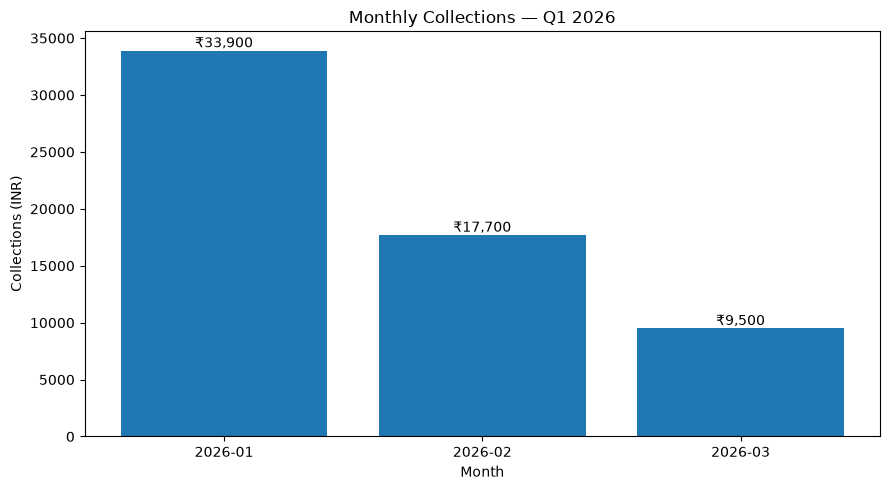

In [14]:
import matplotlib.pyplot as plt

# Create the monthly collections chart
plt.figure(figsize=(9, 5))

plt.bar(
    monthly_collections["Month"],
    monthly_collections["Total_Collections"]
)

plt.title("Monthly Collections — Q1 2026")
plt.xlabel("Month")
plt.ylabel("Collections (INR)")
plt.ticklabel_format(axis="y", style="plain")

# Add value labels above each bar
for index, value in enumerate(
    monthly_collections["Total_Collections"]
):
    plt.text(
        index,
        value,
        f"₹{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

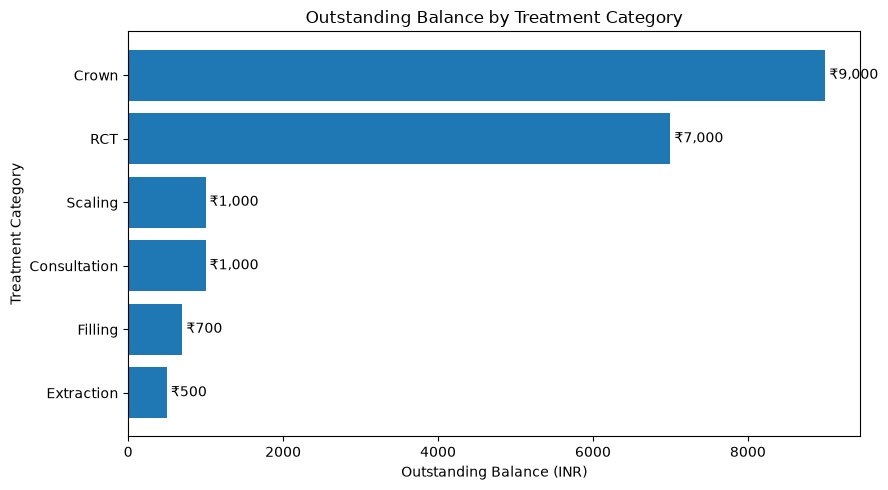

In [15]:
# Sort treatments by outstanding balance, highest first
outstanding_chart = treatment_summary.sort_values(
    "Total_Outstanding",
    ascending=True
)

# Create a horizontal bar chart
plt.figure(figsize=(9, 5))

plt.barh(
    outstanding_chart["Treatment_Category"],
    outstanding_chart["Total_Outstanding"]
)

plt.title("Outstanding Balance by Treatment Category")
plt.xlabel("Outstanding Balance (INR)")
plt.ylabel("Treatment Category")
plt.ticklabel_format(axis="x", style="plain")

# Add value labels
for index, value in enumerate(
    outstanding_chart["Total_Outstanding"]
):
    plt.text(
        value,
        index,
        f" ₹{value:,.0f}",
        va="center"
    )

plt.tight_layout()
plt.show()

In [16]:
# Define the report output directory
report_dir = project_dir / "05_Report"
report_dir.mkdir(parents=True, exist_ok=True)

# 1. Export overall financial KPIs
overall_kpis = pd.DataFrame({
    "Metric": [
        "Total Charges",
        "Total Collections",
        "Outstanding Balance",
        "Collection Rate (%)"
    ],
    "Value": [
        total_charges,
        total_collections,
        total_outstanding,
        round(collection_rate, 2)
    ]
})

overall_kpis.to_csv(
    report_dir / "overall_financial_kpis.csv",
    index=False
)

# 2. Export monthly collections
monthly_collections.to_csv(
    report_dir / "monthly_collections.csv",
    index=False
)

# 3. Export treatment-level financial summary
treatment_summary.to_csv(
    report_dir / "treatment_financial_summary.csv",
    index=False
)

print("Analysis outputs exported successfully.")
print("Output directory:", report_dir)
print("\nFiles created:")
for file_path in sorted(report_dir.glob("*.csv")):
    print("-", file_path.name)

Analysis outputs exported successfully.
Output directory: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\05_Report

Files created:
- monthly_collections.csv
- overall_financial_kpis.csv
- treatment_financial_summary.csv


In [17]:
# Verify that all three exported reports can be read
kpi_check = pd.read_csv(
    report_dir / "overall_financial_kpis.csv"
)

monthly_check = pd.read_csv(
    report_dir / "monthly_collections.csv"
)

treatment_check = pd.read_csv(
    report_dir / "treatment_financial_summary.csv"
)

print("OVERALL KPI REPORT")
display(kpi_check)

print("\nMONTHLY COLLECTIONS REPORT")
display(monthly_check)

print("\nTREATMENT FINANCIAL SUMMARY")
display(treatment_check)

# Verify the key totals
print("\nEXPORT VALIDATION")
print("KPI total charges correct:",
      kpi_check.loc[kpi_check["Metric"] == "Total Charges", "Value"].iloc[0] == 80300)

print("Monthly collections total correct:",
      monthly_check["Total_Collections"].sum() == 61100)

print("Treatment outstanding total correct:",
      treatment_check["Total_Outstanding"].sum() == 19200)

OVERALL KPI REPORT


,Metric,Value
0,Total Charges,80300.00
1,Total Collections,61100.00
2,Outstanding Balance,19200.00
3,Collection Rate (%),76.09



MONTHLY COLLECTIONS REPORT


,Month,Total_Collections
0,2026-01,33900
1,2026-02,17700
2,2026-03,9500



TREATMENT FINANCIAL SUMMARY


,Treatment_Category,Total_Charges,Total_Collections,Total_Outstanding,Collection_Rate_Percent
0,Crown,30000,21000,9000,70.00
1,RCT,28000,21000,7000,75.00
2,Scaling,9000,8000,1000,88.89
3,Filling,5000,4300,700,86.00
4,Extraction,4800,4300,500,89.58
5,Consultation,3500,2500,1000,71.43



EXPORT VALIDATION
KPI total charges correct: True
Monthly collections total correct: True
Treatment outstanding total correct: True


In [18]:
# Confirm the main Python analysis outputs
expected_files = [
    project_dir / "03_Python" / "BHA_Dental_Clinic_Analysis.ipynb",
    report_dir / "overall_financial_kpis.csv",
    report_dir / "monthly_collections.csv",
    report_dir / "treatment_financial_summary.csv",
]

print("BHA PYTHON ANALYSIS — FILE CHECK")
print("-" * 45)

for file_path in expected_files:
    print(f"{file_path.name}: {'Found' if file_path.exists() else 'Missing'}")

print("\nFINAL FINANCIAL CHECK")
print(f"Total Charges: ₹{total_charges:,.0f}")
print(f"Total Collections: ₹{total_collections:,.0f}")
print(f"Outstanding Balance: ₹{total_outstanding:,.0f}")
print(f"Collection Rate: {collection_rate:.2f}%")

BHA PYTHON ANALYSIS — FILE CHECK
---------------------------------------------
BHA_Dental_Clinic_Analysis.ipynb: Missing
overall_financial_kpis.csv: Found
monthly_collections.csv: Found
treatment_financial_summary.csv: Found

FINAL FINANCIAL CHECK
Total Charges: ₹80,300
Total Collections: ₹61,100
Outstanding Balance: ₹19,200
Collection Rate: 76.09%


In [19]:
# Check the expected notebook location
notebook_path = (
    project_dir
    / "03_Python"
    / "BHA_Dental_Clinic_Analysis.ipynb"
)

print("Expected location:", notebook_path)
print("Notebook exists there:", notebook_path.exists())

# Check whether the Python folder exists and list its contents
python_dir = project_dir / "03_Python"

print("\nPython folder exists:", python_dir.exists())

if python_dir.exists():
    print("Files in Python folder:")
    for item in python_dir.iterdir():
        print("-", item.name)

Expected location: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\03_Python\BHA_Dental_Clinic_Analysis.ipynb
Notebook exists there: False

Python folder exists: False


In [20]:
# List the contents of the BHA project directory
print("Project directory:", project_dir)
print("Project directory exists:", project_dir.exists())

print("\nFolders and files currently present:")
for item in sorted(project_dir.iterdir()):
    item_type = "Folder" if item.is_dir() else "File"
    print(f"{item_type}: {item.name}")

Project directory: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics
Project directory exists: True

Folders and files currently present:
Folder: 01_Raw_Data
Folder: 02_Cleaned_Data
Folder: 03_Python_Analysis
Folder: 04_PowerBI_Dashboard
Folder: 05_Report
Folder: 05_Reports
Folder: 06_Screenshots
Folder: 07_Documentation


In [21]:
# Check the actual Python analysis folder
python_dir = project_dir / "03_Python_Analysis"

print("Python analysis folder exists:", python_dir.exists())

if python_dir.exists():
    print("\nContents of 03_Python_Analysis:")
    for item in sorted(python_dir.iterdir()):
        print("-", item.name)

# Check both report folders
for folder_name in ["05_Report", "05_Reports"]:
    folder_path = project_dir / folder_name
    print(f"\n{folder_name} exists:", folder_path.exists())

    if folder_path.exists():
        print("Files:")
        for item in sorted(folder_path.iterdir()):
            print("-", item.name)

Python analysis folder exists: True

Contents of 03_Python_Analysis:
- BHA_Dental_Clinic_Analysis.ipynb

05_Report exists: True
Files:
- monthly_collections.csv
- overall_financial_kpis.csv
- treatment_financial_summary.csv

05_Reports exists: True
Files:


In [22]:
# Use the actual project folder names
notebook_path = (
    project_dir
    / "03_Python_Analysis"
    / "BHA_Dental_Clinic_Analysis.ipynb"
)

report_files = [
    report_dir / "overall_financial_kpis.csv",
    report_dir / "monthly_collections.csv",
    report_dir / "treatment_financial_summary.csv",
]

print("BHA PYTHON ANALYSIS — FILE CHECK")
print("-" * 45)

print(
    "Notebook:",
    "Found" if notebook_path.exists() else "Missing"
)

for file_path in report_files:
    print(
        f"{file_path.name}:",
        "Found" if file_path.exists() else "Missing"
    )

print("\nFINANCIAL RECONCILIATION")
print(
    "Charges = Collections + Outstanding:",
    total_charges == total_collections + total_outstanding
)

BHA PYTHON ANALYSIS — FILE CHECK
---------------------------------------------
Notebook: Found
overall_financial_kpis.csv: Found
monthly_collections.csv: Found
treatment_financial_summary.csv: Found

FINANCIAL RECONCILIATION
Charges = Collections + Outstanding: True


In [23]:
# Verify the Python analysis report and supporting files
expected_files = [
    project_dir / "03_Python_Analysis" / "BHA_Dental_Clinic_Analysis.ipynb",
    report_dir / "BHA_Dental_Clinic_Python_Analysis_Report.md",
    report_dir / "overall_financial_kpis.csv",
    report_dir / "monthly_collections.csv",
    report_dir / "treatment_financial_summary.csv",
]

print("BHA PROJECT DELIVERABLE CHECK")
print("-" * 45)

for file_path in expected_files:
    status = "Found" if file_path.exists() else "Missing"
    print(f"{file_path.name}: {status}")

BHA PROJECT DELIVERABLE CHECK
---------------------------------------------
BHA_Dental_Clinic_Analysis.ipynb: Found
BHA_Dental_Clinic_Python_Analysis_Report.md: Found
overall_financial_kpis.csv: Found
monthly_collections.csv: Found
treatment_financial_summary.csv: Found


In [24]:
# Check whether Python's built-in SQLite database module is available
import sqlite3

print("SQLite version:", sqlite3.sqlite_version)
print("SQLite is available for SQL analysis.")

SQLite version: 3.50.4
SQLite is available for SQL analysis.


In [25]:
# Create a dedicated folder for SQL analysis
sql_dir = project_dir / "04_SQL_Analysis"
sql_dir.mkdir(parents=True, exist_ok=True)

# Define the SQLite database path
database_path = sql_dir / "bha_dental_analytics.db"

print("SQL folder:", sql_dir)
print("SQL folder exists:", sql_dir.exists())
print("Database path:", database_path)
print("Database already exists:", database_path.exists())

SQL folder: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\04_SQL_Analysis
SQL folder exists: True
Database path: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\04_SQL_Analysis\bha_dental_analytics.db
Database already exists: False


In [26]:
# Connect to the SQLite database
connection = sqlite3.connect(database_path)

# Load validated transaction data into a SQL table
transactions.to_sql(
    name="dental_transactions",
    con=connection,
    if_exists="replace",
    index=False
)

print("Transaction data loaded into SQLite.")
print("Database:", database_path)

Transaction data loaded into SQLite.
Database: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\04_SQL_Analysis\bha_dental_analytics.db


In [27]:
# Verify the table using SQL
row_count = pd.read_sql_query(
    "SELECT COUNT(*) AS total_records FROM dental_transactions;",
    connection
)

print("SQL ROW COUNT")
display(row_count)

# Preview the first five records using SQL
preview = pd.read_sql_query(
    """
    SELECT
        Transaction_ID,
        Visit_Date,
        Treatment_Category,
        Amount_Charged,
        Amount_Collected,
        Outstanding_Amount
    FROM dental_transactions
    ORDER BY Visit_Date
    LIMIT 5;
    """,
    connection
)

print("\nSQL DATA PREVIEW")
display(preview)

SQL ROW COUNT


,total_records
0,35



SQL DATA PREVIEW


,Transaction_ID,Visit_Date,Treatment_Category,Amount_Charged,Amount_Collected,Outstanding_Amount
0,T001,2026-01-05 00:00:00,Consultation,500,500,0
1,T002,2026-01-06 00:00:00,Scaling,1500,1500,0
2,T003,2026-01-07 00:00:00,RCT,4000,2500,1500
3,T004,2026-01-08 00:00:00,Extraction,1200,1200,0
4,T005,2026-01-09 00:00:00,Consultation,500,0,500


In [28]:
# Overall financial KPIs using SQL

kpi_query = """
SELECT
    SUM(Amount_Charged) AS Total_Charges,
    SUM(Amount_Collected) AS Total_Collections,
    SUM(Outstanding_Amount) AS Total_Outstanding,
    ROUND(
        100.0 * SUM(Amount_Collected)
        / NULLIF(SUM(Amount_Charged), 0),
        2
    ) AS Collection_Rate_Percent
FROM dental_transactions;
"""

sql_kpis = pd.read_sql_query(kpi_query, connection)

display(sql_kpis)

,Total_Charges,Total_Collections,Total_Outstanding,Collection_Rate_Percent
0,80300,61100,19200,76.09


In [29]:
# Monthly collections using SQL

monthly_query = """
SELECT
    strftime('%Y-%m', Visit_Date) AS Month,
    SUM(Amount_Collected) AS Total_Collections
FROM dental_transactions
GROUP BY strftime('%Y-%m', Visit_Date)
ORDER BY Month;
"""

sql_monthly = pd.read_sql_query(monthly_query, connection)

display(sql_monthly)

,Month,Total_Collections
0,2026-01,33900
1,2026-02,17700
2,2026-03,9500


In [30]:
# Treatment-level financial analysis using SQL

treatment_query = """
SELECT
    Treatment_Category,
    SUM(Amount_Charged) AS Total_Charges,
    SUM(Amount_Collected) AS Total_Collections,
    SUM(Outstanding_Amount) AS Total_Outstanding,
    ROUND(
        100.0 * SUM(Amount_Collected)
        / NULLIF(SUM(Amount_Charged), 0),
        2
    ) AS Collection_Rate_Percent
FROM dental_transactions
GROUP BY Treatment_Category
ORDER BY Total_Charges DESC;
"""

sql_treatment = pd.read_sql_query(
    treatment_query,
    connection
)

display(sql_treatment)

,Treatment_Category,Total_Charges,Total_Collections,Total_Outstanding,Collection_Rate_Percent
0,Crown,30000,21000,9000,70.00
1,RCT,28000,21000,7000,75.00
2,Scaling,9000,8000,1000,88.89
3,Filling,5000,4300,700,86.00
4,Extraction,4800,4300,500,89.58
5,Consultation,3500,2500,1000,71.43


In [31]:
# Reconcile SQL outputs with Python outputs

# 1. Overall financial KPIs
python_kpis = {
    "Total_Charges": total_charges,
    "Total_Collections": total_collections,
    "Total_Outstanding": total_outstanding,
}

sql_kpi_row = sql_kpis.iloc[0]

overall_check = all(
    abs(float(sql_kpi_row[column]) - float(value)) < 0.01
    for column, value in python_kpis.items()
)

# 2. Monthly collections
monthly_check = (
    sql_monthly["Month"].tolist()
    == monthly_collections["Month"].tolist()
    and sql_monthly["Total_Collections"].tolist()
    == monthly_collections["Total_Collections"].tolist()
)

# 3. Treatment-level financial totals
python_treatment_check = (
    treatment_summary[
        [
            "Treatment_Category",
            "Total_Charges",
            "Total_Collections",
            "Total_Outstanding",
        ]
    ]
    .sort_values("Total_Charges", ascending=False)
    .reset_index(drop=True)
)

sql_treatment_check = (
    sql_treatment[
        [
            "Treatment_Category",
            "Total_Charges",
            "Total_Collections",
            "Total_Outstanding",
        ]
    ]
    .reset_index(drop=True)
)

treatment_check = python_treatment_check.equals(
    sql_treatment_check
)

# Display reconciliation results
reconciliation = pd.DataFrame({
    "Validation": [
        "Overall financial KPIs",
        "Monthly collections",
        "Treatment-level financial totals",
    ],
    "Passed": [
        overall_check,
        monthly_check,
        treatment_check,
    ],
})

display(reconciliation)

print(
    "\nAll SQL-to-Python checks passed:",
    overall_check and monthly_check and treatment_check
)

,Validation,Passed
0,Overall financial KPIs,True
1,Monthly collections,True
2,Treatment-level financial totals,True



All SQL-to-Python checks passed: True


In [32]:
# Save reusable SQL query files

sql_queries = {
    "01_overall_financial_kpis.sql": kpi_query,
    "02_monthly_collections.sql": monthly_query,
    "03_treatment_financial_summary.sql": treatment_query,
}

for filename, query in sql_queries.items():
    file_path = sql_dir / filename
    file_path.write_text(query.strip() + "\n", encoding="utf-8")
    print(f"Saved: {file_path.name}")

print("\nSQL query files saved successfully.")

Saved: 01_overall_financial_kpis.sql
Saved: 02_monthly_collections.sql
Saved: 03_treatment_financial_summary.sql

SQL query files saved successfully.


In [33]:
# Export SQL analysis results to CSV

sql_exports = {
    "sql_overall_financial_kpis.csv": sql_kpis,
    "sql_monthly_collections.csv": sql_monthly,
    "sql_treatment_financial_summary.csv": sql_treatment,
}

for filename, result_df in sql_exports.items():
    output_path = sql_dir / filename
    result_df.to_csv(output_path, index=False)
    print(f"Exported: {output_path.name}")

print("\nAll SQL result files exported successfully.")

Exported: sql_overall_financial_kpis.csv
Exported: sql_monthly_collections.csv
Exported: sql_treatment_financial_summary.csv

All SQL result files exported successfully.


In [34]:
# Create the SQL analysis report

sql_report = """
# BHA Dental Clinic Analytics — SQL Analysis Report

## 1. Project Overview

This project demonstrates SQL-based financial analysis for a
fictional dental clinic dataset covering January–March 2026.

**Important:** All records and financial figures are fictional and
are intended solely for portfolio demonstration.

## 2. Tools and Technologies

- SQLite
- SQL
- Python
- pandas
- Jupyter Notebook

## 3. Dataset

- Source: BHA Dental Clinic cleaned demonstration workbook
- Records analyzed: 35 transactions
- Analysis period: January–March 2026
- SQL table: `dental_transactions`

## 4. Overall Financial KPIs

| Metric | Result |
|---|---:|
| Total Charges | ₹80,300 |
| Total Collections | ₹61,100 |
| Total Outstanding | ₹19,200 |
| Collection Rate | 76.09% |

## 5. Monthly Collections

| Month | Collections |
|---|---:|
| January 2026 | ₹33,900 |
| February 2026 | ₹17,700 |
| March 2026 | ₹9,500 |

Total collections across the three months were ₹61,100.

## 6. Treatment-Level Analysis

| Treatment | Charges | Collections | Outstanding | Collection Rate |
|---|---:|---:|---:|---:|
| Crown | ₹30,000 | ₹21,000 | ₹9,000 | 70.00% |
| RCT | ₹28,000 | ₹21,000 | ₹7,000 | 75.00% |
| Scaling | ₹9,000 | ₹8,000 | ₹1,000 | 88.89% |
| Filling | ₹5,000 | ₹4,300 | ₹700 | 86.00% |
| Extraction | ₹4,800 | ₹4,300 | ₹500 | 89.58% |
| Consultation | ₹3,500 | ₹2,500 | ₹1,000 | 71.43% |

Crown and RCT together account for ₹16,000 of the ₹19,200
outstanding balance in this demonstration dataset.

## 7. SQL Techniques Demonstrated

- `SUM()` for financial aggregation
- `GROUP BY` for monthly and treatment summaries
- `strftime()` for month-level grouping
- `ROUND()` for collection-rate calculations
- `NULLIF()` to guard against division by zero
- `ORDER BY` for chronological and financial ranking
- Python–SQL reconciliation for validation

## 8. Validation

SQL outputs were compared against the corresponding Python results.

- Overall financial KPIs: Passed
- Monthly collections: Passed
- Treatment-level financial totals: Passed

All three SQL-to-Python reconciliation checks passed.

## 9. Deliverables

- SQLite database: `bha_dental_analytics.db`
- SQL queries for overall KPIs, monthly collections and treatment summaries
- CSV exports of all three SQL analyses

## 10. Limitations

The dataset is fictional and small. The findings should not be
interpreted as actual clinic performance or used to make real
operational or financial decisions.

## 11. Conclusion

This project demonstrates a reproducible SQL workflow for
summarizing dental transaction data, analyzing collections and
outstanding balances, and validating SQL results against Python.
"""

report_path = sql_dir / "BHA_Dental_Clinic_SQL_Analysis_Report.md"
report_path.write_text(sql_report.strip() + "\n", encoding="utf-8")

print("SQL report saved:", report_path)
print("File exists:", report_path.exists())

SQL report saved: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\04_SQL_Analysis\BHA_Dental_Clinic_SQL_Analysis_Report.md
File exists: True


In [35]:
# Final SQL deliverables verification

expected_files = [
    "bha_dental_analytics.db",
    "01_overall_financial_kpis.sql",
    "02_monthly_collections.sql",
    "03_treatment_financial_summary.sql",
    "sql_overall_financial_kpis.csv",
    "sql_monthly_collections.csv",
    "sql_treatment_financial_summary.csv",
    "BHA_Dental_Clinic_SQL_Analysis_Report.md",
]

file_check = pd.DataFrame({
    "File": expected_files,
    "Exists": [
        (sql_dir / filename).is_file()
        for filename in expected_files
    ],
})

display(file_check)

# Verify the SQL table's record count
final_count = pd.read_sql_query(
    "SELECT COUNT(*) AS total_records FROM dental_transactions;",
    connection,
)

print("Database transaction count:", int(final_count.iloc[0, 0]))
print("All expected files exist:", bool(file_check["Exists"].all()))
print(
    "Final verification passed:",
    bool(file_check["Exists"].all())
    and int(final_count.iloc[0, 0]) == 35
)

,File,Exists
0,bha_dental_analytics.db,True
1,01_overall_financial_kpis.sql,True
2,02_monthly_collections.sql,True
3,03_treatment_financial_summary.sql,True
4,sql_overall_financial_kpis.csv,True
5,sql_monthly_collections.csv,True
6,sql_treatment_financial_summary.csv,True
7,BHA_Dental_Clinic_SQL_Analysis_Report.md,True


Database transaction count: 35
All expected files exist: True
Final verification passed: True


In [36]:
# Step 34: Audit the complete BHA project structure

from pathlib import Path
import pandas as pd

project_dir = (
    Path.home()
    / "Desktop"
    / "BHA_Dental_Clinic_Analytics"
)

print("PROJECT ROOT")
print(project_dir)
print("Root exists:", project_dir.is_dir())

# List folders and files without modifying anything
structure = []

for item in sorted(project_dir.rglob("*")):
    if item.is_file():
        structure.append({
            "Type": "File",
            "Path": str(item.relative_to(project_dir)),
            "Size_KB": round(item.stat().st_size / 1024, 2),
        })
    elif item.is_dir():
        structure.append({
            "Type": "Folder",
            "Path": str(item.relative_to(project_dir)),
            "Size_KB": None,
        })

structure_df = pd.DataFrame(
    structure,
    columns=["Type", "Path", "Size_KB"]
)

display(structure_df)

print("\nTotal folders:", sum(
    1 for item in project_dir.rglob("*") if item.is_dir()
))
print("Total files:", sum(
    1 for item in project_dir.rglob("*") if item.is_file()
))

PROJECT ROOT
C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics
Root exists: True


,Type,Path,Size_KB
0,Folder,01_Raw_Data,NaN
1,File,01_Raw_Data\BHA_Dental_Clinic_Transactions.xlsx,14.88
2,Folder,02_Cleaned_Data,NaN
3,File,02_Cleaned_Data\BHA_Dental_Clinic_Cleaned.xlsx,24.77
4,File,02_Cleaned_Data\~$BHA_Dental_Clinic_Cleaned.xlsx,0.16
5,Folder,03_Python_Analysis,NaN
6,File,03_Python_Analysis\BHA_Dental_Clinic_Analysis....,143.26
7,Folder,04_PowerBI_Dashboard,NaN
8,File,04_PowerBI_Dashboard\BHA_Dental_Clinic_Analyti...,47.08
9,Folder,04_SQL_Analysis,NaN



Total folders: 9
Total files: 19


In [37]:
# Step 35: Read the existing README without modifying it

readme_path = project_dir / "07_Documentation" / "README.md"

if readme_path.is_file():
    readme_content = readme_path.read_text(encoding="utf-8")

    print("README path:", readme_path)
    print("README length:", len(readme_content), "characters")
    print("\n" + "=" * 70)
    print(readme_content)
    print("=" * 70)
else:
    print("README.md was not found at:", readme_path)

README path: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\07_Documentation\README.md
README length: 7496 characters

# BHA Dental Clinic Analytics — Financial Performance Dashboard

## Project Overview

This project demonstrates how healthcare financial transaction data can be transformed into actionable insights using Microsoft Excel and Power BI.

The dashboard summarizes dental treatment charges, collections, outstanding balances, collection rates, and monthly collection trends. It is designed as a demonstration of financial reporting and healthcare analytics capabilities relevant to dental clinics and small healthcare providers.

**Organization:** Bhardwaj Healthcare Analytics (BHA)  
**Project Type:** Healthcare Financial Analytics  
**Reporting Period:** January–March 2026  
**Currency:** Indian Rupees (INR)  
**Dataset:** 35 fictional transaction records  
**Primary Tool:** Microsoft Power BI Desktop

> **Data disclaimer:** This project uses fictional demonstration data.

In [40]:
# Step 36B: Create improved README draft safely

readme_lines = [
    "# BHA Dental Clinic Analytics",
    "## Healthcare Financial Analytics | Python | SQL | Power BI",
    "",
    "## Project Overview",
    "",
    "This project demonstrates an end-to-end healthcare financial analytics workflow using fictional dental clinic transaction data for January–March 2026. It combines Excel data preparation, Python analysis, SQL queries, financial reconciliation, and a Power BI dashboard.",
    "",
    "**Organization:** Bhardwaj Healthcare Analytics (BHA)  ",
    "**Reporting period:** January–March 2026  ",
    "**Currency:** INR  ",
    "**Dataset:** 35 fictional transactions",
    "",
    "> **Data disclaimer:** All records and figures are fictional and intended solely for portfolio demonstration. They do not represent actual clinic performance or real patient transactions.",
    "",
    "## Business Questions",
    "",
    "- What were the total charges and collections?",
    "- What balance remained outstanding?",
    "- What was the collection rate?",
    "- How did collections vary by month and treatment category?",
    "- Do Python and SQL produce consistent results?",
    "",
    "## Key Financial Results",
    "",
    "| Metric | Result |",
    "|---|---:|",
    "| Total Charges | ₹80,300 |",
    "| Total Collections | ₹61,100 |",
    "| Outstanding Balance | ₹19,200 |",
    "| Collection Rate | 76.09% |",
    "| Transactions | 35 |",
    "",
    "## Monthly Collections",
    "",
    "| Month | Collections |",
    "|---|---:|",
    "| January 2026 | ₹33,900 |",
    "| February 2026 | ₹17,700 |",
    "| March 2026 | ₹9,500 |",
    "| **Total** | **₹61,100** |",
    "",
    "Collections declined across the three months in this fictional sample. The short period does not establish a reliable real-world trend.",
    "",
    "## Treatment-Level Analysis",
    "",
    "| Treatment | Charges | Collections | Outstanding | Collection Rate |",
    "|---|---:|---:|---:|---:|",
    "| Crown | ₹30,000 | ₹21,000 | ₹9,000 | 70.00% |",
    "| RCT | ₹28,000 | ₹21,000 | ₹7,000 | 75.00% |",
    "| Scaling | ₹9,000 | ₹8,000 | ₹1,000 | 88.89% |",
    "| Filling | ₹5,000 | ₹4,300 | ₹700 | 86.00% |",
    "| Extraction | ₹4,800 | ₹4,300 | ₹500 | 89.58% |",
    "| Consultation | ₹3,500 | ₹2,500 | ₹1,000 | 71.43% |",
    "| **Total** | **₹80,300** | **₹61,100** | **₹19,200** | **76.09%** |",
    "",
    "Crown and RCT together account for ₹16,000 of the ₹19,200 outstanding balance in this demonstration dataset.",
    "",
    "## Tools and Workflow",
    "",
    "1. **Excel:** Structured source workbook and cleaned transaction data.",
    "2. **Python and pandas:** Data inspection, quality checks, calculations, summaries, charts, and CSV exports.",
    "3. **SQLite and SQL:** Overall KPIs, monthly collections, and treatment-level analysis.",
    "4. **Power BI:** DAX measures, KPI cards, and financial visualizations.",
    "5. **Validation:** SQL outputs reconciled against Python results.",
    "",
    "## Validation",
    "",
    "Data-quality checks included missing values, duplicate transaction IDs, duplicate rows, and outstanding-balance calculations.",
    "",
    "All three SQL-to-Python reconciliation checks passed:",
    "",
    "- Overall financial KPIs",
    "- Monthly collections",
    "- Treatment-level financial totals",
    "",
    "## Power BI Dashboard",
    "",
    "Dashboard page: **Financial Performance**",
    "",
    "- Total Charges by Treatment Category",
    "- Monthly Collections — Q1 2026",
    "- Charges vs Collections by Treatment",
    "- Outstanding Balance by Treatment Category",
    "",
    "## Project Structure",
    "",
    "```text",
    "BHA_Dental_Clinic_Analytics/",
    "├── 01_Raw_Data/",
    "├── 02_Cleaned_Data/",
    "├── 03_Python_Analysis/",
    "├── 04_PowerBI_Dashboard/",
    "├── 04_SQL_Analysis/",
    "├── 05_Report/",
    "├── 06_Screenshots/",
    "└── 07_Documentation/",
    "```",
    "",
    "The SQL folder contains the SQLite database, three reusable SQL queries, three CSV result files, and the SQL analysis report. The Python report and its CSV outputs are in `05_Report`.",
    "",
    "## Limitations",
    "",
    "- The dataset contains only 35 fictional transactions across three months.",
    "- It cannot establish actual clinic performance or reliable long-term trends.",
    "- Charges and collections do not, by themselves, establish accounting revenue or profit.",
    "- Operating expenses, treatment costs, and insurance reimbursement are outside the current scope.",
    "",
    "## Future Enhancements",
    "",
    "- Add more synthetic records and reporting periods.",
    "- Add interactive date filters and additional Power BI measures.",
    "- Expand automated data-quality checks.",
    "- Add cost and profitability analysis using clearly defined data.",
    "- Publish reproducible notebooks, SQL scripts, and dashboard screenshots.",
    "",
    "## About",
    "",
    "Developed as a portfolio project for **Bhardwaj Healthcare Analytics (BHA)** to demonstrate healthcare data preparation, Python, SQL, financial reconciliation, and Power BI reporting.",
    ""
]

readme_draft_path = (
    project_dir / "07_Documentation" / "README_DRAFT.md"
)

readme_draft_path.write_text(
    "\n".join(readme_lines),
    encoding="utf-8"
)

print("Draft saved:", readme_draft_path)
print("Draft exists:", readme_draft_path.is_file())
print("Original README preserved:", readme_path.is_file())
print("Draft size:", readme_draft_path.stat().st_size, "bytes")
print("Draft line count:", len(readme_lines))

Draft saved: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\07_Documentation\README_DRAFT.md
Draft exists: True
Original README preserved: True
Draft size: 4529 bytes
Draft line count: 119


In [39]:
# Verify the README paths and confirm the original is safe

from pathlib import Path

project_dir = Path.home() / "Desktop" / "BHA_Dental_Clinic_Analytics"
readme_path = project_dir / "07_Documentation" / "README.md"
readme_draft_path = project_dir / "07_Documentation" / "README_DRAFT.md"

print("Project exists:", project_dir.is_dir())
print("Original README exists:", readme_path.is_file())
print("Draft already exists:", readme_draft_path.exists())

if readme_path.is_file():
    print("Original README size:", readme_path.stat().st_size, "bytes")

Project exists: True
Original README exists: True
Draft already exists: False
Original README size: 7814 bytes


In [41]:
# Step 37: Validate README content and project paths

draft_text = readme_draft_path.read_text(encoding="utf-8")

checks = {
    "Fictional-data disclaimer included":
        "fictional" in draft_text.lower(),
    "Python analysis documented":
        "Python and pandas" in draft_text,
    "SQL analysis documented":
        "SQLite and SQL" in draft_text,
    "Power BI documented":
        "Power BI" in draft_text,
    "SQL-Python validation documented":
        "reconciliation checks passed" in draft_text,
    "Correct Power BI folder name":
        "04_PowerBI_Dashboard" in draft_text,
    "Correct SQL folder name":
        "04_SQL_Analysis" in draft_text,
    "Correct reports folder name":
        "05_Report" in draft_text,
    "Original README still exists":
        readme_path.is_file(),
}

validation_df = pd.DataFrame({
    "Check": list(checks.keys()),
    "Passed": list(checks.values()),
})

display(validation_df)

print("\nAll README checks passed:", all(checks.values()))

,Check,Passed
0,Fictional-data disclaimer included,True
1,Python analysis documented,True
2,SQL analysis documented,True
3,Power BI documented,True
4,SQL-Python validation documented,True
5,Correct Power BI folder name,True
6,Correct SQL folder name,True
7,Correct reports folder name,True
8,Original README still exists,True



All README checks passed: True


In [42]:
# Step 38: Review files for GitHub publication
# This cell only lists files; it does not upload, move, or delete anything.

publication_review = []

for item in sorted(project_dir.rglob("*")):
    if not item.is_file():
        continue

    relative_path = str(item.relative_to(project_dir))
    suffix = item.suffix.lower()
    size_mb = item.stat().st_size / (1024 * 1024)

    if item.name.startswith("~$"):
        recommendation = "Exclude: temporary Excel lock file"
    elif suffix in [".pbix", ".db", ".xlsx", ".ipynb"]:
        recommendation = "Review before publishing"
    elif suffix in [".md", ".sql", ".csv", ".png", ".jpg", ".jpeg"]:
        recommendation = "Usually suitable; inspect contents"
    else:
        recommendation = "Review file type and purpose"

    publication_review.append({
        "File": relative_path,
        "Size_MB": round(size_mb, 3),
        "Recommendation": recommendation,
    })

publication_df = pd.DataFrame(publication_review)
display(publication_df)

print("\nFiles reviewed:", len(publication_df))
print("No files were modified.")

,File,Size_MB,Recommendation
0,01_Raw_Data\BHA_Dental_Clinic_Transactions.xlsx,0.015,Review before publishing
1,02_Cleaned_Data\BHA_Dental_Clinic_Cleaned.xlsx,0.024,Review before publishing
2,02_Cleaned_Data\~$BHA_Dental_Clinic_Cleaned.xlsx,0.000,Exclude: temporary Excel lock file
3,03_Python_Analysis\BHA_Dental_Clinic_Analysis....,0.174,Review before publishing
4,04_PowerBI_Dashboard\BHA_Dental_Clinic_Analyti...,0.046,Review before publishing
5,04_SQL_Analysis\01_overall_financial_kpis.sql,0.000,Usually suitable; inspect contents
6,04_SQL_Analysis\02_monthly_collections.sql,0.000,Usually suitable; inspect contents
7,04_SQL_Analysis\03_treatment_financial_summary...,0.000,Usually suitable; inspect contents
8,04_SQL_Analysis\bha_dental_analytics.db,0.008,Review before publishing
9,04_SQL_Analysis\BHA_Dental_Clinic_SQL_Analysis...,0.003,Usually suitable; inspect contents



Files reviewed: 20
No files were modified.


In [43]:

# Step 39: Read-only notebook publication safety check
# This cell does not edit or save changes to the notebook.

import json
import re
from pathlib import Path

notebook_path = (
    project_dir
    / "03_Python_Analysis"
    / "BHA_Dental_Clinic_Analysis.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])
code_cells = [c for c in cells if c.get("cell_type") == "code"]

saved_output_count = sum(
    len(c.get("outputs", [])) for c in code_cells
)

executed_cell_count = sum(
    c.get("execution_count") is not None for c in code_cells
)

# Look for common secrets and machine-specific paths.
checks = {
    "Possible API key or access token": re.compile(
        r"(?i)(api[_-]?key|access[_-]?token|secret[_-]?key)\s*[:=]\s*['\"][^'\"]+['\"]"
    ),
    "Possible password": re.compile(
        r"(?i)(password|passwd|pwd)\s*[:=]\s*['\"][^'\"]+['\"]"
    ),
    "Windows user-specific path": re.compile(
        r"(?i)[A-Z]:\\Users\\[^\\\s'\"]+"
    ),
    "Kaggle-specific path": re.compile(
        r"(?i)/kaggle/(working|input)/"
    ),
    "Python installation-specific path": re.compile(
        r"(?i)[A-Z]:\\Python\d+"
    ),
}

findings = []

for cell_index, cell in enumerate(cells):
    source = "".join(cell.get("source", []))
    output_text = ""

    for output in cell.get("outputs", []):
        data = output.get("data", {})
        output_text += str(data.get("text/plain", ""))
        output_text += str(data.get("text/html", ""))
        output_text += str(output.get("text", ""))

        if "traceback" in output:
            output_text += "\n".join(output["traceback"])

    combined_text = source + "\n" + output_text

    for label, pattern in checks.items():
        if pattern.search(combined_text):
            findings.append({
                "Cell": cell_index,
                "Finding": label
            })

print("Notebook:", notebook_path.name)
print("Total cells:", len(cells))
print("Code cells:", len(code_cells))
print("Executed code cells:", executed_cell_count)
print("Saved outputs:", saved_output_count)
print("File size (KB):", round(notebook_path.stat().st_size / 1024, 2))

print("\nPotential publication findings:")
if findings:
    display(pd.DataFrame(findings).drop_duplicates())
else:
    print("No matches for the selected patterns.")

print("\nRead-only check complete. Notebook was not modified.")


Notebook: BHA_Dental_Clinic_Analysis.ipynb
Total cells: 41
Code cells: 40
Executed code cells: 39
Saved outputs: 59
File size (KB): 190.97

Potential publication findings:
No matches for the selected patterns.

Read-only check complete. Notebook was not modified.


In [44]:

# Step 40: Summarize notebook outputs before publication
# Read-only: no notebook cells or outputs are changed.

from collections import Counter

output_types = Counter()
saved_errors = []
output_cells = 0

for cell_index, cell in enumerate(notebook.get("cells", [])):
    outputs = cell.get("outputs", [])

    if outputs:
        output_cells += 1

    for output in outputs:
        output_type = output.get("output_type", "unknown")
        output_types[output_type] += 1

        if output_type == "error":
            saved_errors.append({
                "Cell": cell_index,
                "Error": output.get("ename", "Unknown"),
                "Message": output.get("evalue", "")
            })

print("Cells containing saved outputs:", output_cells)
print("\nOutput types:")
display(pd.DataFrame(
    [{"Output type": key, "Count": value}
     for key, value in output_types.items()]
))

print("\nSaved error outputs:", len(saved_errors))
if saved_errors:
    display(pd.DataFrame(saved_errors))
else:
    print("No saved error outputs found.")

print("\nNotebook remains unchanged.")


Cells containing saved outputs: 39

Output types:


,Output type,Count
0,stream,40
1,execute_result,2
2,display_data,17



Saved error outputs: 0
No saved error outputs found.

Notebook remains unchanged.


In [45]:

# Step 41: Inspect the README draft
# This cell only reads and displays the draft.

readme_draft_path = (
    project_dir / "07_Documentation" / "README_DRAFT.md"
)

if readme_draft_path.exists():
    draft_text = readme_draft_path.read_text(encoding="utf-8")

    print("Draft exists:", True)
    print("Characters:", len(draft_text))
    print("Lines:", len(draft_text.splitlines()))
    print("\n--- README DRAFT PREVIEW ---\n")
    print(draft_text[:12000])
else:
    print("README draft not found:", readme_draft_path)


Draft exists: True
Characters: 4297
Lines: 118

--- README DRAFT PREVIEW ---

# BHA Dental Clinic Analytics
## Healthcare Financial Analytics | Python | SQL | Power BI

## Project Overview

This project demonstrates an end-to-end healthcare financial analytics workflow using fictional dental clinic transaction data for January–March 2026. It combines Excel data preparation, Python analysis, SQL queries, financial reconciliation, and a Power BI dashboard.

**Organization:** Bhardwaj Healthcare Analytics (BHA)  
**Reporting period:** January–March 2026  
**Currency:** INR  
**Dataset:** 35 fictional transactions

> **Data disclaimer:** All records and figures are fictional and intended solely for portfolio demonstration. They do not represent actual clinic performance or real patient transactions.

## Business Questions

- What were the total charges and collections?
- What balance remained outstanding?
- What was the collection rate?
- How did collections vary by month and treatment cat

In [46]:

# Step 42: Check README destinations before publication
# Read-only: no files are changed.

root_readme = project_dir / "README.md"
documentation_readme = project_dir / "07_Documentation" / "README.md"
draft_readme = project_dir / "07_Documentation" / "README_DRAFT.md"

for label, path in [
    ("Project-root README", root_readme),
    ("Existing documentation README", documentation_readme),
    ("Improved README draft", draft_readme),
]:
    print(f"{label}:")
    print("  Path:", path)
    print("  Exists:", path.exists())
    if path.exists():
        print("  Size (bytes):", path.stat().st_size)
    print()

print("No files were created, overwritten, or deleted.")


Project-root README:
  Path: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\README.md
  Exists: False

Existing documentation README:
  Path: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\07_Documentation\README.md
  Exists: True
  Size (bytes): 7814

Improved README draft:
  Path: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\07_Documentation\README_DRAFT.md
  Exists: True
  Size (bytes): 4529

No files were created, overwritten, or deleted.


In [47]:

# Step 43: Create a GitHub-ready README at the project root
# Creates a new file only; refuses to overwrite an existing root README.

root_readme = project_dir / "README.md"
draft_readme_path = project_dir / "07_Documentation" / "README_DRAFT.md"

if root_readme.exists():
    raise FileExistsError(
        f"Refusing to overwrite existing README: {root_readme}"
    )

if not draft_readme_path.exists():
    raise FileNotFoundError(
        f"README draft not found: {draft_readme_path}"
    )

readme_text = draft_readme_path.read_text(encoding="utf-8")

# Correct the actual folder tree without renaming project folders.
old_tree = """BHA_Dental_Clinic_Analytics/
├── 01_Raw_Data/
├── 02_Cleaned_Data/
├── 03_Python_Analysis/
├── 04_PowerBI_Dashboard/
├── 04_SQL_Analysis/
├── 05_Report/
├── 06_Screenshots/
└── 07_Documentation/"""

new_tree = """BHA_Dental_Clinic_Analytics/
├── 01_Raw_Data/
├── 02_Cleaned_Data/
├── 03_Python_Analysis/
├── 04_PowerBI_Dashboard/
├── 04_SQL_Analysis/
├── 05_Report/
├── 05_Reports/                  # Extra folder; currently empty
├── 06_Screenshots/
├── 07_Documentation/
└── README.md"""

if old_tree not in readme_text:
    raise ValueError(
        "Expected folder tree was not found. No file was created."
    )

readme_text = readme_text.replace(old_tree, new_tree)

# Add links to useful project artifacts.
dashboard_section = """## Power BI Dashboard

Dashboard page: **Financial Performance**

- Total Charges by Treatment Category
- Monthly Collections — Q1 2026
- Charges vs Collections by Treatment
- Outstanding Balance by Treatment Category"""

dashboard_section_updated = """## Power BI Dashboard

Dashboard page: **Financial Performance**

- Total Charges by Treatment Category
- Monthly Collections — Q1 2026
- Charges vs Collections by Treatment
- Outstanding Balance by Treatment Category

### Dashboard Screenshot

![BHA Dental Clinic Financial Performance Dashboard](06_Screenshots/BHA_Dental_Clinic_Financial_Performance.png)

### Project Artifacts

- [Python analysis notebook](03_Python_Analysis/BHA_Dental_Clinic_Analysis.ipynb)
- [Power BI dashboard file](04_PowerBI_Dashboard/BHA_Dental_Clinic_Analytics.pbix)
- [Python analysis report](05_Report/BHA_Dental_Clinic_Python_Analysis_Report.md)
- [SQL analysis report](04_SQL_Analysis/BHA_Dental_Clinic_SQL_Analysis_Report.md)
- [SQL scripts folder](04_SQL_Analysis/)
- [Documentation folder](07_Documentation/)"""

if dashboard_section not in readme_text:
    raise ValueError(
        "Expected dashboard section was not found. No file was created."
    )

readme_text = readme_text.replace(
    dashboard_section, dashboard_section_updated
)

# Confirm key referenced files exist before writing.
required_files = [
    project_dir / "03_Python_Analysis" / "BHA_Dental_Clinic_Analysis.ipynb",
    project_dir / "04_PowerBI_Dashboard" / "BHA_Dental_Clinic_Analytics.pbix",
    project_dir / "05_Report" / "BHA_Dental_Clinic_Python_Analysis_Report.md",
    project_dir / "04_SQL_Analysis" / "BHA_Dental_Clinic_SQL_Analysis_Report.md",
    project_dir / "06_Screenshots" / "BHA_Dental_Clinic_Financial_Performance.png",
]

missing_files = [str(p) for p in required_files if not p.exists()]

if missing_files:
    print("Missing referenced files:")
    for path in missing_files:
        print("-", path)
    raise FileNotFoundError(
        "No README was created because one or more linked files are missing."
    )

root_readme.write_text(readme_text, encoding="utf-8")

# Verify the new file.
saved_text = root_readme.read_text(encoding="utf-8")

print("Root README created:", root_readme)
print("Size (bytes):", root_readme.stat().st_size)
print("Fictional-data disclaimer present:",
      "All records and figures are fictional" in saved_text)
print("Dashboard screenshot link present:",
      "06_Screenshots/BHA_Dental_Clinic_Financial_Performance.png" in saved_text)
print("Python notebook link present:",
      "03_Python_Analysis/BHA_Dental_Clinic_Analysis.ipynb" in saved_text)
print("Existing documentation README preserved:",
      (project_dir / "07_Documentation" / "README.md").exists())
print("Original draft preserved:", draft_readme_path.exists())


Root README created: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\README.md
Size (bytes): 5213
Fictional-data disclaimer present: True
Dashboard screenshot link present: True
Python notebook link present: True
Existing documentation README preserved: True
Original draft preserved: True


In [48]:

# Step 44: Validate README links and common placeholders
# Read-only: does not modify any files.

import re
from pathlib import Path

root_readme = project_dir / "README.md"
readme_text = root_readme.read_text(encoding="utf-8")

# Find Markdown links and image references.
references = re.findall(
    r"!?\[[^\]]*\]\(([^)]+)\)",
    readme_text
)

local_references = []
external_references = []

for reference in references:
    reference = reference.strip()

    if (
        reference.startswith(("http://", "https://", "mailto:"))
        or reference.startswith("#")
    ):
        external_references.append(reference)
        continue

    # Remove an optional anchor from a local path.
    relative_path = reference.split("#", 1)[0]
    target = (project_dir / relative_path).resolve()

    local_references.append({
        "Reference": reference,
        "Exists": target.exists(),
        "Type": "Folder" if target.is_dir() else (
            "File" if target.is_file() else "Missing"
        ),
    })

print("README:", root_readme)
print("Local references:", len(local_references))
print("External links or anchors:", len(external_references))

if local_references:
    display(pd.DataFrame(local_references))

missing_links = [
    item for item in local_references if not item["Exists"]
]

placeholder_patterns = [
    r"(?i)\bTODO\b",
    r"(?i)\bFIXME\b",
    r"\[insert.*?\]",
    r"<your[-_ ].*?>",
]

placeholder_hits = []
for pattern in placeholder_patterns:
    if re.search(pattern, readme_text):
        placeholder_hits.append(pattern)

print("\nMissing local references:", len(missing_links))
print("Common placeholder patterns found:", len(placeholder_hits))

if placeholder_hits:
    print("Patterns:", placeholder_hits)

print("\nValidation completed; no files were changed.")


README: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\README.md
Local references: 7
External links or anchors: 0


,Reference,Exists,Type
0,06_Screenshots/BHA_Dental_Clinic_Financial_Per...,True,File
1,03_Python_Analysis/BHA_Dental_Clinic_Analysis....,True,File
2,04_PowerBI_Dashboard/BHA_Dental_Clinic_Analyti...,True,File
3,05_Report/BHA_Dental_Clinic_Python_Analysis_Re...,True,File
4,04_SQL_Analysis/BHA_Dental_Clinic_SQL_Analysis...,True,File
5,04_SQL_Analysis/,True,Folder
6,07_Documentation/,True,Folder



Missing local references: 0
Common placeholder patterns found: 0

Validation completed; no files were changed.


In [49]:

# Step 45: Inspect workbook sheets, column names, and SQLite tables
# Read-only: no workbook or database content is modified.

import sqlite3
import pandas as pd

raw_path = project_dir / "01_Raw_Data" / "BHA_Dental_Clinic_Transactions.xlsx"
cleaned_path = project_dir / "02_Cleaned_Data" / "BHA_Dental_Clinic_Cleaned.xlsx"
db_path = project_dir / "04_SQL_Analysis" / "bha_dental_analytics.db"

# Inspect Excel workbook structure.
for label, path in [
    ("RAW WORKBOOK", raw_path),
    ("CLEANED WORKBOOK", cleaned_path),
]:
    print(f"\n--- {label} ---")
    if not path.exists():
        print("File missing:", path)
        continue

    workbook = pd.ExcelFile(path)
    print("File:", path.name)
    print("Sheets:", workbook.sheet_names)

    for sheet in workbook.sheet_names:
        df = pd.read_excel(path, sheet_name=sheet)
        print(f"\nSheet: {sheet}")
        print("Rows:", len(df))
        print("Columns:", list(df.columns))
        print("Potential personal-data column names:",
              [
                  col for col in df.columns
                  if any(term in str(col).lower() for term in [
                      "name", "phone", "mobile", "email", "address",
                      "dob", "birth", "aadhaar", "patient"
                  ])
              ])

# Inspect SQLite database structure without writing to it.
print("\n--- SQLITE DATABASE ---")
if db_path.exists():
    with sqlite3.connect(f"file:{db_path.as_posix()}?mode=ro", uri=True) as conn:
        tables = pd.read_sql_query(
            """
            SELECT name
            FROM sqlite_master
            WHERE type = 'table'
            ORDER BY name
            """,
            conn
        )
        display(tables)

        for table_name in tables["name"]:
            # Table names come from sqlite_master; quote safely for PRAGMA.
            escaped_name = table_name.replace('"', '""')
            schema = pd.read_sql_query(
                f'PRAGMA table_info("{escaped_name}")',
                conn
            )
            row_count = pd.read_sql_query(
                f'SELECT COUNT(*) AS row_count FROM "{escaped_name}"',
                conn
            ).iloc[0]["row_count"]

            print(f"\nTable: {table_name}")
            print("Rows:", row_count)
            print("Columns:", schema["name"].tolist())
else:
    print("Database missing:", db_path)

print("\nInspection complete. No files were modified.")



--- RAW WORKBOOK ---
File: BHA_Dental_Clinic_Transactions.xlsx
Sheets: ['Clinic_Transactions', 'Clinic_Summary', 'Monthly_Summary']

Sheet: Clinic_Transactions
Rows: 35
Columns: ['Transaction_ID     ', ' Visit_ID', ' Visit_Date', 'Patient_ID', 'Treatment_Category', 'Amount_Charged', 'Amount_Collected', 'Outstanding_Amount']
Potential personal-data column names: ['Patient_ID']

Sheet: Clinic_Summary
Rows: 4
Columns: ['Metric', 'Value']
Potential personal-data column names: []

Sheet: Monthly_Summary
Rows: 4
Columns: ['Month', 'Total_Charged', 'Total_Collected', 'Outstanding', 'Collection_Rate']
Potential personal-data column names: []

--- CLEANED WORKBOOK ---
File: BHA_Dental_Clinic_Cleaned.xlsx
Sheets: ['Sheet2', 'Cleaned_Transactions', 'PowerBI_Data', 'Clinic_Summary', 'Monthly_Summary']

Sheet: Sheet2
Rows: 9
Columns: ['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2']
Potential personal-data column names: ['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2']

Sheet: Cleaned_Transactions
Rows: 35
Colu

,name
0,dental_transactions



Table: dental_transactions
Rows: 35
Columns: ['Transaction_ID', 'Visit_ID', 'Visit_Date', 'Patient_ID', 'Treatment_Category', 'Amount_Charged', 'Amount_Collected', 'Outstanding_Amount', 'Calculated_Outstanding']

Inspection complete. No files were modified.


In [50]:

# Step 46: Investigate suspicious cleaned-workbook fields
# Read-only inspection; no files are changed.

cleaned_path = project_dir / "02_Cleaned_Data" / "BHA_Dental_Clinic_Cleaned.xlsx"

# Inspect Sheet2, which may contain leftover content or formatting.
sheet2 = pd.read_excel(cleaned_path, sheet_name="Sheet2", header=None)
print("--- Sheet2 contents (up to 10 rows) ---")
display(sheet2.head(10))

# Inspect only the extra / unnamed columns in Cleaned_Transactions.
cleaned_df = pd.read_excel(
    cleaned_path,
    sheet_name="Cleaned_Transactions"
)

suspicious_columns = [
    col for col in cleaned_df.columns
    if str(col).startswith("Unnamed") or
       str(col).strip() == "Data Validation Results"
]

print("\n--- Suspicious columns ---")
if suspicious_columns:
    display(cleaned_df[suspicious_columns].head(10))
else:
    print("No suspicious columns found.")

# Inspect a few distinct Patient_ID values, not complete patient rows.
print("\n--- Patient_ID format check ---")
for sheet in ["Cleaned_Transactions", "PowerBI_Data"]:
    df = pd.read_excel(cleaned_path, sheet_name=sheet)
    if "Patient_ID" in df.columns:
        values = (
            df["Patient_ID"]
            .dropna()
            .astype(str)
            .drop_duplicates()
            .head(5)
            .tolist()
        )
        print(f"{sheet}: {values}")

print("\nRead-only inspection complete.")


--- Sheet2 contents (up to 10 rows) ---


,0,1,2
0,NaN,NaN,NaN
1,NaN,NaN,NaN
2,Row Labels,Sum of Amount_Charged,Sum of Amount_Collected
3,Consultation,3500,2500
4,Crown,30000,21000
5,Extraction,4800,4300
6,Filling,5000,4300
7,RCT,28000,21000
8,Scaling,9000,8000
9,Grand Total,80300,61100



--- Suspicious columns ---


,Unnamed: 8,Unnamed: 9,Unnamed: 10,Data Validation Results,Unnamed: 12
0,NaN,NaN,NaN,Total transaction records,35
1,NaN,NaN,NaN,Unique transaction IDs,35
2,NaN,NaN,NaN,Missing required values,0
3,NaN,NaN,NaN,Incorrect outstanding calculations,0
4,NaN,NaN,NaN,Financial reconciliation checks passed,3 of 3
5,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN



--- Patient_ID format check ---
Cleaned_Transactions: ['P001', 'P002', 'P003', 'P004', 'P005']
PowerBI_Data: ['P001', 'P002', 'P003', 'P004', 'P005']

Read-only inspection complete.


In [51]:

# Step 47: Build the proposed GitHub publication checklist
# Read-only: does not move, delete, or modify files.

publication_items = []

exclude_names = {
    "~$BHA_Dental_Clinic_Cleaned.xlsx",
    "README_DRAFT.md",
}

for item in sorted(project_dir.rglob("*")):
    if not item.is_file():
        continue

    rel = item.relative_to(project_dir).as_posix()

    if item.name in exclude_names:
        status = "EXCLUDE"
        reason = "Temporary Excel lock file or working README draft"
    elif item == project_dir / "07_Documentation" / "README.md":
        status = "REVIEW"
        reason = "Older documentation README; root README is now primary"
    elif item.suffix.lower() in {".xlsx", ".pbix", ".db", ".ipynb"}:
        status = "REVIEW"
        reason = "Confirm content and usefulness before publishing"
    else:
        status = "PROPOSE"
        reason = "Likely useful portfolio artifact"

    publication_items.append({
        "Path": rel,
        "Status": status,
        "Reason": reason,
    })

publication_df = pd.DataFrame(publication_items)
display(publication_df)

print("\nTotal files:", len(publication_df))
print("Proposed:", int((publication_df["Status"] == "PROPOSE").sum()))
print("Review:", int((publication_df["Status"] == "REVIEW").sum()))
print("Exclude:", int((publication_df["Status"] == "EXCLUDE").sum()))
print("\nNo files were modified.")


,Path,Status,Reason
0,01_Raw_Data/BHA_Dental_Clinic_Transactions.xlsx,REVIEW,Confirm content and usefulness before publishing
1,02_Cleaned_Data/BHA_Dental_Clinic_Cleaned.xlsx,REVIEW,Confirm content and usefulness before publishing
2,02_Cleaned_Data/~$BHA_Dental_Clinic_Cleaned.xlsx,EXCLUDE,Temporary Excel lock file or working README draft
3,03_Python_Analysis/BHA_Dental_Clinic_Analysis....,REVIEW,Confirm content and usefulness before publishing
4,04_PowerBI_Dashboard/BHA_Dental_Clinic_Analyti...,REVIEW,Confirm content and usefulness before publishing
5,04_SQL_Analysis/01_overall_financial_kpis.sql,PROPOSE,Likely useful portfolio artifact
6,04_SQL_Analysis/02_monthly_collections.sql,PROPOSE,Likely useful portfolio artifact
7,04_SQL_Analysis/03_treatment_financial_summary...,PROPOSE,Likely useful portfolio artifact
8,04_SQL_Analysis/bha_dental_analytics.db,REVIEW,Confirm content and usefulness before publishing
9,04_SQL_Analysis/BHA_Dental_Clinic_SQL_Analysis...,PROPOSE,Likely useful portfolio artifact



Total files: 21
Proposed: 13
Review: 6
Exclude: 2

No files were modified.


In [52]:

# Step 48: Create a safe Git ignore file
# Refuses to overwrite an existing .gitignore.

gitignore_path = project_dir / ".gitignore"

gitignore_content = """# Python and Jupyter temporary files
__pycache__/
*.py[cod]
.ipynb_checkpoints/

# Environment and local configuration
.env
.env.*
!.env.example
.venv/
venv/

# Temporary Excel lock files
~$*.xlsx
~$*.xls

# Operating system files
.DS_Store
Thumbs.db
desktop.ini

# Editor settings
.vscode/
"""

if gitignore_path.exists():
    print("An existing .gitignore was found.")
    print("It has NOT been overwritten.")
    print("\nCurrent contents:\n")
    print(gitignore_path.read_text(encoding="utf-8"))
else:
    gitignore_path.write_text(gitignore_content, encoding="utf-8")
    print("Created:", gitignore_path)
    print("\nContents:\n")
    print(gitignore_path.read_text(encoding="utf-8"))

print("\nNo project data files were modified or deleted.")


Created: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics\.gitignore

Contents:

# Python and Jupyter temporary files
__pycache__/
*.py[cod]
.ipynb_checkpoints/

# Environment and local configuration
.env
.env.*
!.env.example
.venv/
venv/

# Temporary Excel lock files
~$*.xlsx
~$*.xls

# Operating system files
.DS_Store
Thumbs.db
desktop.ini

# Editor settings
.vscode/


No project data files were modified or deleted.


In [53]:

# Step 49: Inspect Git status without changing the repository
import subprocess

def run_git(args):
    result = subprocess.run(
        ["git", *args],
        cwd=project_dir,
        capture_output=True,
        text=True,
        shell=False
    )
    return result

repo_check = run_git(["rev-parse", "--is-inside-work-tree"])

if repo_check.returncode != 0:
    print("This project folder is not currently inside a Git repository.")
    print(repo_check.stderr.strip() or repo_check.stdout.strip())
else:
    print("Git repository detected.")

    branch = run_git(["branch", "--show-current"])
    print("\nCurrent branch:")
    print(branch.stdout.strip() or "(detached HEAD or branch not named)")

    status = run_git(["status", "--short", "--branch"])
    print("\nGit status:")
    print(status.stdout.strip() or "(no changes reported)")

    staged = run_git(["diff", "--cached", "--name-status"])
    print("\nAlready staged files:")
    print(staged.stdout.strip() or "(none)")

    remote = run_git(["remote", "-v"])
    print("\nConfigured remotes:")
    print(remote.stdout.strip() or "(none configured)")

print("\nRead-only check complete. Nothing was staged, committed, or uploaded.")


This project folder is not currently inside a Git repository.
fatal: not a git repository (or any of the parent directories): .git

Read-only check complete. Nothing was staged, committed, or uploaded.


In [54]:
from pathlib import Path
import subprocess

project_dir = Path(
    r"C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics"
)

# Safety checks before initializing Git
assert project_dir.exists(), f"Project folder not found: {project_dir}"
assert (project_dir / "README.md").exists(), "Root README.md is missing"
assert (project_dir / ".gitignore").exists(), ".gitignore is missing"

# Do not initialize a second repository accidentally
if (project_dir / ".git").exists():
    print("Git is already initialized in this folder. No changes made.")
else:
    result = subprocess.run(
        ["git", "init", "-b", "main"],
        cwd=project_dir,
        capture_output=True,
        text=True
    )

    print(result.stdout)
    if result.returncode != 0:
        print(result.stderr)
    else:
        print("Git initialized successfully.")

print("\nProject folder:", project_dir)

Initialized empty Git repository in C:/Users/acharya/Desktop/BHA_Dental_Clinic_Analytics/.git/

Git initialized successfully.

Project folder: C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics


In [55]:
import subprocess

result = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=project_dir,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

## No commits yet on main
?? .gitignore
?? 01_Raw_Data/
?? 02_Cleaned_Data/
?? 03_Python_Analysis/
?? 04_PowerBI_Dashboard/
?? 04_SQL_Analysis/
?? 05_Report/
?? 06_Screenshots/
?? 07_Documentation/
?? README.md



In [56]:
from pathlib import Path

print("PROJECT FILE INVENTORY\n")

for path in sorted(project_dir.rglob("*")):
    if not path.is_file():
        continue

    # Ignore Git's internal files
    if ".git" in path.parts:
        continue

    relative_path = path.relative_to(project_dir)
    size_kb = path.stat().st_size / 1024

    print(f"{str(relative_path):75} {size_kb:10.2f} KB")

print("\nPUBLICATION REVIEW FLAGS\n")

for path in sorted(project_dir.rglob("*")):
    if not path.is_file() or ".git" in path.parts:
        continue

    name = path.name.lower()

    if "readme_draft" in name:
        print("EXCLUDE DRAFT:", path.relative_to(project_dir))
    elif name.startswith("~$"):
        print("EXCLUDE TEMPORARY FILE:", path.relative_to(project_dir))
    elif name.endswith((".env", ".pem", ".key")):
        print("CHECK SENSITIVE FILE:", path.relative_to(project_dir))

PROJECT FILE INVENTORY

.gitignore                                                                        0.31 KB
01_Raw_Data\BHA_Dental_Clinic_Transactions.xlsx                                  14.88 KB
02_Cleaned_Data\BHA_Dental_Clinic_Cleaned.xlsx                                   24.77 KB
02_Cleaned_Data\~$BHA_Dental_Clinic_Cleaned.xlsx                                  0.16 KB
03_Python_Analysis\BHA_Dental_Clinic_Analysis.ipynb                             251.14 KB
04_PowerBI_Dashboard\BHA_Dental_Clinic_Analytics.pbix                            47.08 KB
04_SQL_Analysis\01_overall_financial_kpis.sql                                     0.31 KB
04_SQL_Analysis\02_monthly_collections.sql                                        0.18 KB
04_SQL_Analysis\03_treatment_financial_summary.sql                                0.39 KB
04_SQL_Analysis\bha_dental_analytics.db                                           8.00 KB
04_SQL_Analysis\BHA_Dental_Clinic_SQL_Analysis_Report.md                    

In [57]:
import re
import json
from pathlib import Path
from openpyxl import load_workbook

# 1. Inspect workbook sheet names, headers, and sample rows
for relative in [
    r"01_Raw_Data\BHA_Dental_Clinic_Transactions.xlsx",
    r"02_Cleaned_Data\BHA_Dental_Clinic_Cleaned.xlsx",
]:
    file_path = project_dir / relative
    print(f"\n--- {relative} ---")
    wb = load_workbook(file_path, read_only=True, data_only=True)

    for ws in wb.worksheets:
        print(f"\nSheet: {ws.title} | rows={ws.max_row}, columns={ws.max_column}")
        for row in ws.iter_rows(min_row=1, max_row=min(ws.max_row, 3), values_only=True):
            print(row[:12])

    wb.close()

# 2. Search text files and notebook source for common risk indicators
patterns = {
    "email address": re.compile(r"\b[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}\b", re.I),
    "phone-like number": re.compile(r"(?<!\d)(?:\+?\d[\d ()-]{8,}\d)(?!\d)"),
    "Windows user path": re.compile(r"C:\\Users\\[^\\\s]+", re.I),
    "possible secret": re.compile(
        r"(api[_-]?key|access[_-]?token|password\s*[:=]|secret\s*[:=])",
        re.I
    ),
}

files_to_scan = [
    project_dir / "README.md",
    project_dir / "07_Documentation" / "README.md",
    project_dir / "04_SQL_Analysis" / "BHA_Dental_Clinic_SQL_Analysis_Report.md",
    project_dir / "05_Report" / "BHA_Dental_Clinic_Python_Analysis_Report.md",
    project_dir / "03_Python_Analysis" / "BHA_Dental_Clinic_Analysis.ipynb",
]

print("\n--- TEXT/NOTEBOOK SAFETY FLAGS ---")
for file_path in files_to_scan:
    if not file_path.exists():
        continue

    content = file_path.read_text(encoding="utf-8", errors="replace")
    if file_path.suffix == ".ipynb":
        try:
            notebook = json.loads(content)
            content = "\n".join(
                str(cell.get("source", ""))
                for cell in notebook.get("cells", [])
            )
        except json.JSONDecodeError:
            print("Could not parse notebook:", file_path.name)
            continue

    for label, pattern in patterns.items():
        matches = list(pattern.finditer(content))
        if matches:
            print(f"REVIEW {label}: {file_path.relative_to(project_dir)} ({len(matches)} match(es))")

print("\nCheck complete. Matches, if any, require manual review; they do not prove a leak.")


--- 01_Raw_Data\BHA_Dental_Clinic_Transactions.xlsx ---

Sheet: Clinic_Transactions | rows=36, columns=8
('Transaction_ID     ', ' Visit_ID', ' Visit_Date', 'Patient_ID', 'Treatment_Category', 'Amount_Charged', 'Amount_Collected', 'Outstanding_Amount')
('T001', 'V001', datetime.datetime(2026, 1, 5, 0, 0), 'P001', 'Consultation', 500, 500, 0)
('T002', 'V002', datetime.datetime(2026, 1, 6, 0, 0), 'P002', 'Scaling', 1500, 1500, 0)

Sheet: Clinic_Summary | rows=5, columns=2
('Metric', 'Value')
('Total Amount Charged', 80300)
('Total Amount Collected', 61100)

Sheet: Monthly_Summary | rows=5, columns=5
('Month', 'Total_Charged', 'Total_Collected', 'Outstanding', 'Collection_Rate')
(datetime.datetime(2026, 1, 1, 0, 0), 44100, 33900, 10200, 0.7687074829931972)
(datetime.datetime(2026, 2, 1, 0, 0), 24200, 17700, 6500, 0.731404958677686)

--- 02_Cleaned_Data\BHA_Dental_Clinic_Cleaned.xlsx ---

Sheet: Sheet2 | rows=10, columns=3
(None, None, None)
(None, None, None)
('Row Labels', 'Sum of Amoun

In [58]:
from pathlib import Path

gitignore_path = project_dir / ".gitignore"
draft_rule = "/07_Documentation/README_DRAFT.md"

content = gitignore_path.read_text(encoding="utf-8")

if draft_rule not in content.splitlines():
    with gitignore_path.open("a", encoding="utf-8", newline="\n") as f:
        f.write("\n# Exclude unpublished draft documentation\n")
        f.write(draft_rule + "\n")
    print("Added draft exclusion to .gitignore.")
else:
    print("Draft exclusion already exists.")

print("\nCurrent .gitignore:\n")
print(gitignore_path.read_text(encoding="utf-8"))

Added draft exclusion to .gitignore.

Current .gitignore:

# Python and Jupyter temporary files
__pycache__/
*.py[cod]
.ipynb_checkpoints/

# Environment and local configuration
.env
.env.*
!.env.example
.venv/
venv/

# Temporary Excel lock files
~$*.xlsx
~$*.xls

# Operating system files
.DS_Store
Thumbs.db
desktop.ini

# Editor settings
.vscode/

# Exclude unpublished draft documentation
/07_Documentation/README_DRAFT.md



In [59]:
import subprocess

project_dir = r"C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics"
github_url = "https://github.com/drsumitbhardwaj10/BHA-Dental-Clinic-Analytics.git"

# Check current remotes
result = subprocess.run(
    ["git", "remote", "-v"],
    cwd=project_dir,
    capture_output=True,
    text=True
)

print("Existing Git remotes:")
print(result.stdout if result.stdout.strip() else "(none)")

# Add origin only if it does not exist
check_origin = subprocess.run(
    ["git", "remote", "get-url", "origin"],
    cwd=project_dir,
    capture_output=True,
    text=True
)

if check_origin.returncode != 0:
    add_result = subprocess.run(
        ["git", "remote", "add", "origin", github_url],
        cwd=project_dir,
        capture_output=True,
        text=True
    )

    if add_result.returncode == 0:
        print("\nAdded GitHub remote: origin")
    else:
        print("\nCould not add remote:")
        print(add_result.stderr)
else:
    existing_url = check_origin.stdout.strip()
    print("\nExisting origin URL:", existing_url)

    if existing_url != github_url:
        print("WARNING: origin points to a different URL. Do not push yet.")

# Show final remote configuration
final_result = subprocess.run(
    ["git", "remote", "-v"],
    cwd=project_dir,
    capture_output=True,
    text=True
)

print("\nFinal remote configuration:")
print(final_result.stdout)

Existing Git remotes:
(none)

Added GitHub remote: origin

Final remote configuration:
origin	https://github.com/drsumitbhardwaj10/BHA-Dental-Clinic-Analytics.git (fetch)
origin	https://github.com/drsumitbhardwaj10/BHA-Dental-Clinic-Analytics.git (push)



In [60]:
import subprocess

project_dir = r"C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics"

commands = [
    ["git", "status", "--short", "--branch"],
    ["git", "ls-files", "--others", "--exclude-standard"],
    ["git", "check-ignore", "-v",
     "02_Cleaned_Data/~$BHA_Dental_Clinic_Cleaned.xlsx"],
    ["git", "check-ignore", "-v",
     "07_Documentation/README_DRAFT.md"],
]

for command in commands:
    result = subprocess.run(
        command,
        cwd=project_dir,
        capture_output=True,
        text=True
    )

    print("\n" + "=" * 70)
    print("$", " ".join(command))
    print("Return code:", result.returncode)
    print(result.stdout.strip() or result.stderr.strip() or "(no output)")


$ git status --short --branch
Return code: 0
## No commits yet on main
?? .gitignore
?? 01_Raw_Data/
?? 02_Cleaned_Data/
?? 03_Python_Analysis/
?? 04_PowerBI_Dashboard/
?? 04_SQL_Analysis/
?? 05_Report/
?? 06_Screenshots/
?? 07_Documentation/
?? README.md

$ git ls-files --others --exclude-standard
Return code: 0
.gitignore
01_Raw_Data/BHA_Dental_Clinic_Transactions.xlsx
02_Cleaned_Data/BHA_Dental_Clinic_Cleaned.xlsx
03_Python_Analysis/BHA_Dental_Clinic_Analysis.ipynb
04_PowerBI_Dashboard/BHA_Dental_Clinic_Analytics.pbix
04_SQL_Analysis/01_overall_financial_kpis.sql
04_SQL_Analysis/02_monthly_collections.sql
04_SQL_Analysis/03_treatment_financial_summary.sql
04_SQL_Analysis/BHA_Dental_Clinic_SQL_Analysis_Report.md
04_SQL_Analysis/bha_dental_analytics.db
04_SQL_Analysis/sql_monthly_collections.csv
04_SQL_Analysis/sql_overall_financial_kpis.csv
04_SQL_Analysis/sql_treatment_financial_summary.csv
05_Report/BHA_Dental_Clinic_Python_Analysis_Report.md
05_Report/monthly_collections.csv
05_R

In [61]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\acharya\Desktop\BHA_Dental_Clinic_Analytics"
)

import subprocess

result = subprocess.run(
    ["git", "ls-files", "--others", "--exclude-standard", "-z"],
    cwd=project_dir,
    capture_output=True,
    check=True
)

relative_paths = [
    p.decode("utf-8")
    for p in result.stdout.split(b"\0")
    if p
]

file_details = []
total_bytes = 0

for relative_path in relative_paths:
    path = project_dir / relative_path
    size = path.stat().st_size
    total_bytes += size

    file_details.append({
        "File": relative_path,
        "Size (MB)": round(size / (1024 * 1024), 2)
    })

print("Eligible files:", len(file_details))
print("Total size (MB):", round(total_bytes / (1024 * 1024), 2))
print("\nLargest files:")
for item in sorted(
    file_details,
    key=lambda x: x["Size (MB)"],
    reverse=True
)[:10]:
    print(f'{item["Size (MB)"]:>7} MB  {item["File"]}')

Eligible files: 20
Total size (MB): 0.45

Largest files:
   0.26 MB  03_Python_Analysis/BHA_Dental_Clinic_Analysis.ipynb
   0.07 MB  06_Screenshots/BHA_Dental_Clinic_Financial_Performance.png
   0.05 MB  04_PowerBI_Dashboard/BHA_Dental_Clinic_Analytics.pbix
   0.02 MB  02_Cleaned_Data/BHA_Dental_Clinic_Cleaned.xlsx
   0.01 MB  01_Raw_Data/BHA_Dental_Clinic_Transactions.xlsx
   0.01 MB  04_SQL_Analysis/bha_dental_analytics.db
   0.01 MB  05_Report/BHA_Dental_Clinic_Python_Analysis_Report.md
   0.01 MB  07_Documentation/README.md
    0.0 MB  .gitignore
    0.0 MB  04_SQL_Analysis/01_overall_financial_kpis.sql
